#  Wine Quality Classification - Project  

### objective: 
* Build a model to classify the quality of wine into multiple categories (3-9 quality scale) based on its physicochemical properties.
*  This is a multiclass classification problem.

### Key Learning Goals:
* Imbalanced Classes: Handle uneven distribution of quality ratings

* Multiclass Classification: Extend beyond binary classification

* Feature Scaling Importance: Understand why scaling matters for certain algorithms

* Model Comparison: Try algorithms that handle multiclass natively

* Classification Metrics: Beyond accuracy - precision, recall, F1-score per class

### importation librairies

In [128]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [129]:
df = pd.read_csv('winequality-red.csv',sep=';')
df.head(20)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.600,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.650,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.580,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.500,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5


In [130]:
df['quality'].unique() # 6 categories of quality of wine (5, 6, 7, 4, 8, 3)

array([5, 6, 7, 4, 8, 3])

In [131]:
df.shape # 1599, 12

(1599, 12)

# EDA

#### Analyse de Forme :
* identify target  =>  quality quality of wine
* num of ligne & colonne  => (1599, 12)
* type des variables(features)  => only numerical features(1 = int/ 11 = float)
* identifiant Nan (missing values)  => 0 Nan
  
+ elimine some columns that arent important like: 'volatile acidity','chlorides','free sulfur dioxide','total sulfur dioxide','density','pH'

#### Analyse de Forme :
* Visualisation de target  => # we can see most wine quality is 5 n 6 , n the least is 8 n 3
*  Comprehension des diff var (seperatly)  => 
*   Visualisation des relations entre features with target and with each others: strong relation with target is those columns => 'fixed acidity', 'citric acid', 'residual sugar', 'sulphates',
       'alcohol'
*   Identification des outliers  => we have a lot of outliers / i will leave them for now since they represent important data

In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [133]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

<Figure size 1200x1000 with 0 Axes>

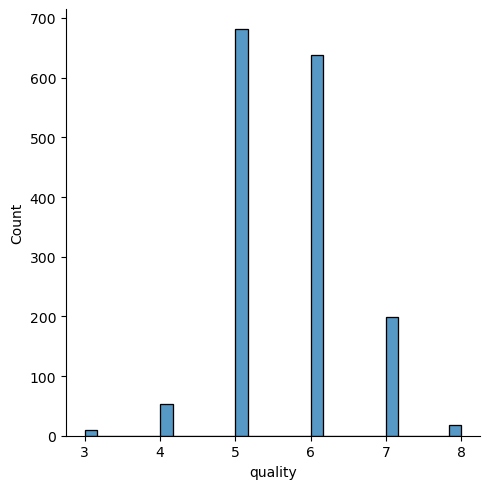

In [134]:
plt.figure(figsize=(12,10))
sns.displot(df['quality']) # we can see most wine quality is 5 n 6 , n the least is 8 n 3

<Axes: ylabel='quality'>

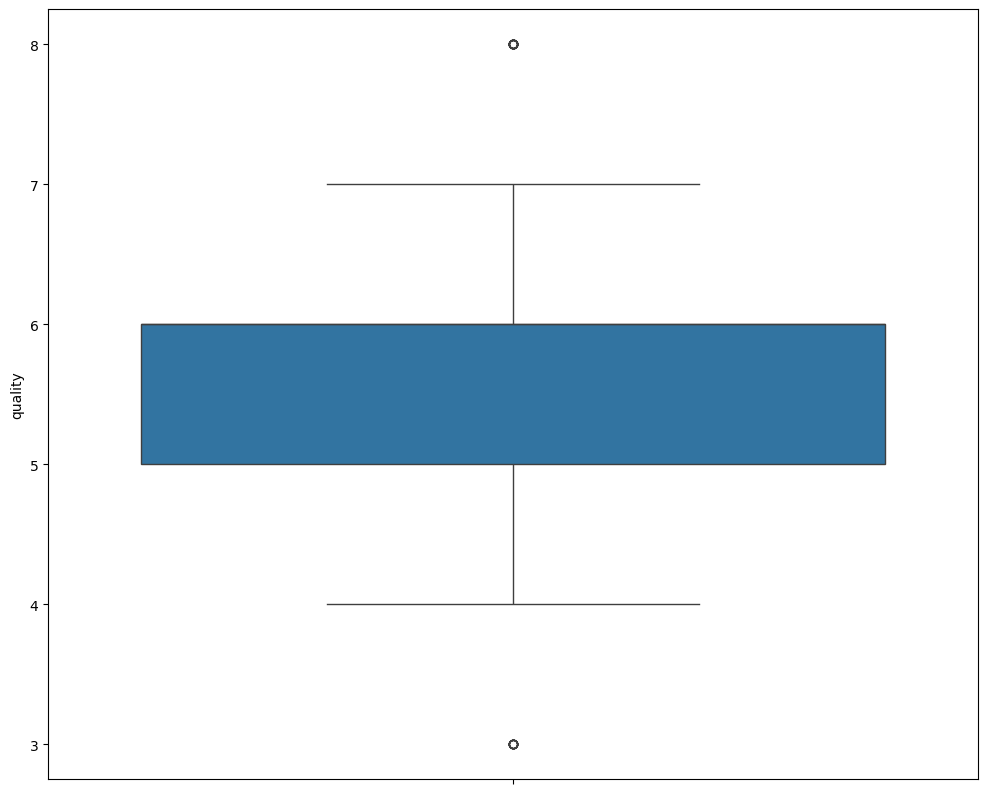

In [135]:
plt.figure(figsize=(12,10))
sns.boxplot(df['quality']) 

In [136]:
df.nunique()

fixed acidity            96
volatile acidity        143
citric acid              80
residual sugar           91
chlorides               153
free sulfur dioxide      60
total sulfur dioxide    144
density                 436
pH                       89
sulphates                96
alcohol                  65
quality                   6
dtype: int64

In [137]:
df.describe() # echelle in columns residualsugar n total sulfur dioxide	is huge comparasing to the other columns => scale the data  

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


<Axes: >

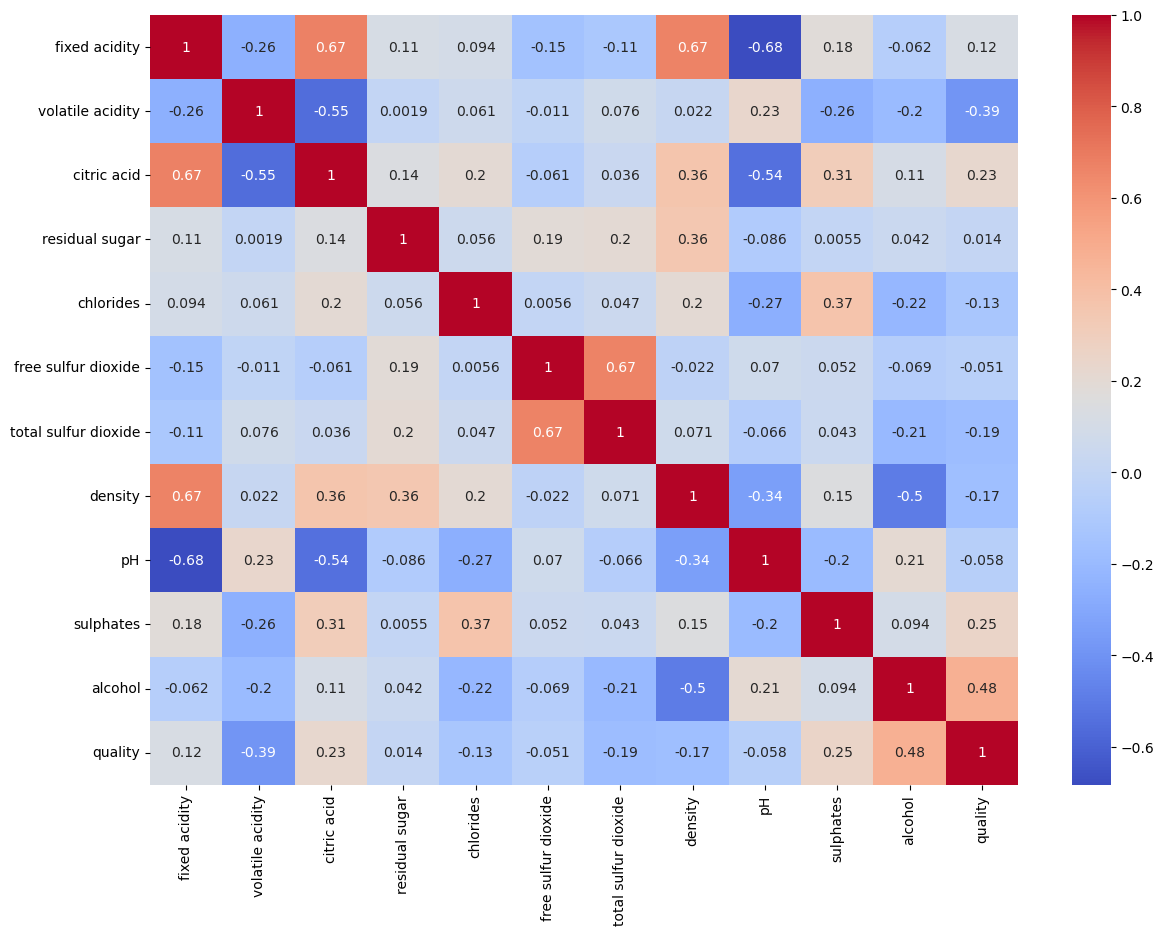

In [138]:
# correlation btw features with each others n target
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm')

In [139]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [140]:
# delete all columns have negative relation with target :['volatile acidity','chlorides','free sulfur dioxide','total sulfur dioxide','density','pH']
df = df.drop(['volatile acidity','chlorides','free sulfur dioxide','total sulfur dioxide','density','pH'],axis=1)
df.head(10)


,fixed acidity,citric acid,residual sugar,sulphates,alcohol,quality
0,7.4,0.00,1.9,0.56,9.4,5
1,7.8,0.00,2.6,0.68,9.8,5
2,7.8,0.04,2.3,0.65,9.8,5
3,11.2,0.56,1.9,0.58,9.8,6
4,7.4,0.00,1.9,0.56,9.4,5
5,7.4,0.00,1.8,0.56,9.4,5
6,7.9,0.06,1.6,0.46,9.4,5
7,7.3,0.00,1.2,0.47,10.0,7
8,7.8,0.02,2.0,0.57,9.5,7
9,7.5,0.36,6.1,0.80,10.5,5


In [141]:
df.describe()

,fixed acidity,citric acid,residual sugar,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.270976,2.538806,0.658149,10.422983,5.636023
std,1.741096,0.194801,1.409928,0.169507,1.065668,0.807569
min,4.600000,0.000000,0.900000,0.330000,8.400000,3.000000
25%,7.100000,0.090000,1.900000,0.550000,9.500000,5.000000
50%,7.900000,0.260000,2.200000,0.620000,10.200000,6.000000
75%,9.200000,0.420000,2.600000,0.730000,11.100000,6.000000
max,15.900000,1.000000,15.500000,2.000000,14.900000,8.000000


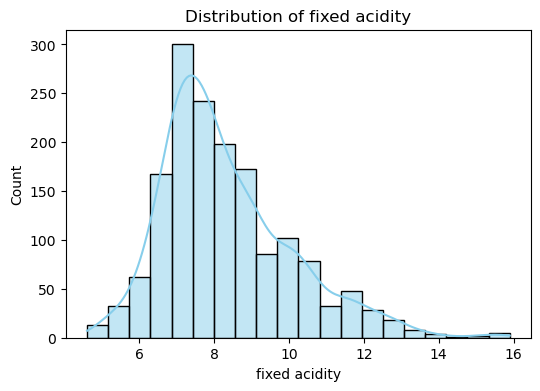

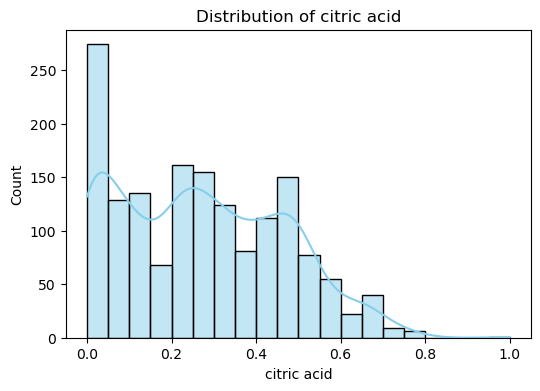

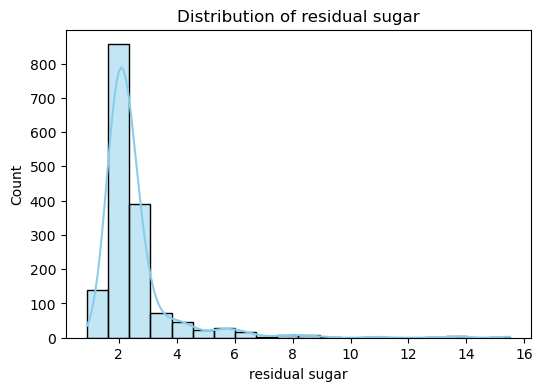

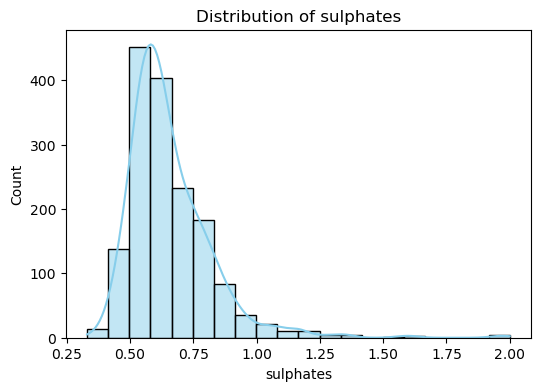

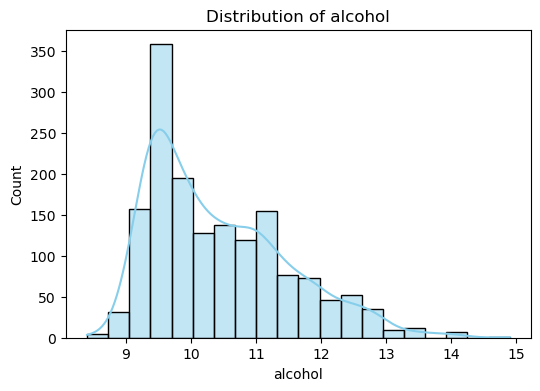

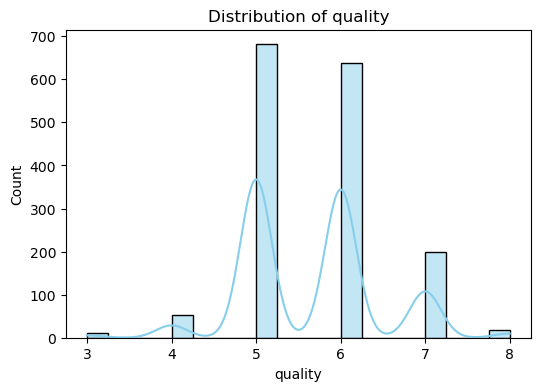

In [142]:
# --- Visualize numerical features ---
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=20, color="skyblue")
    plt.title(f"Distribution of {col}")
    plt.show()


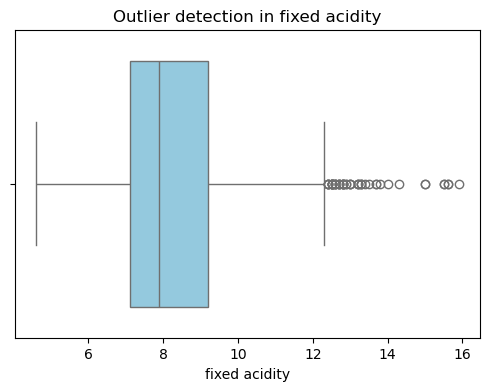

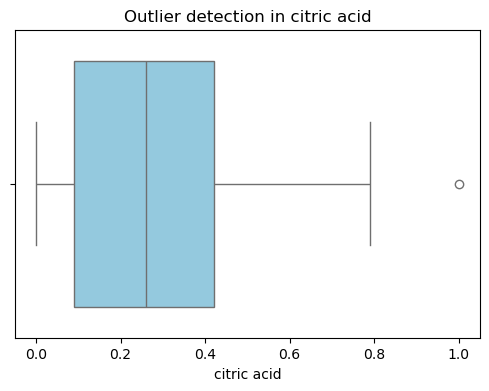

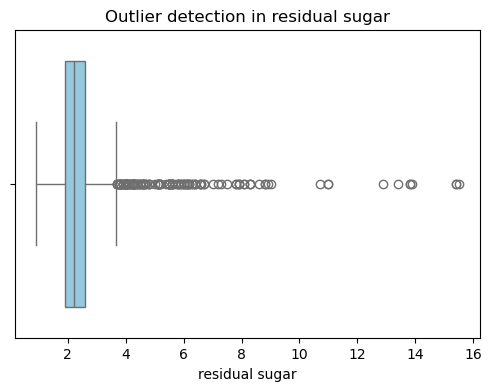

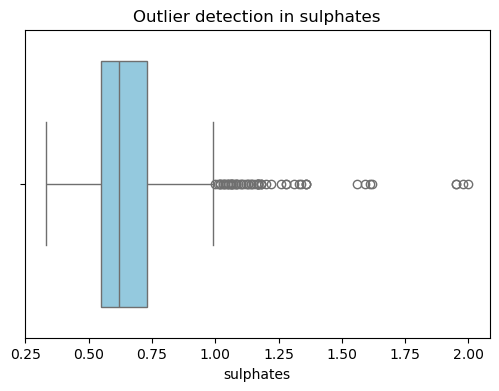

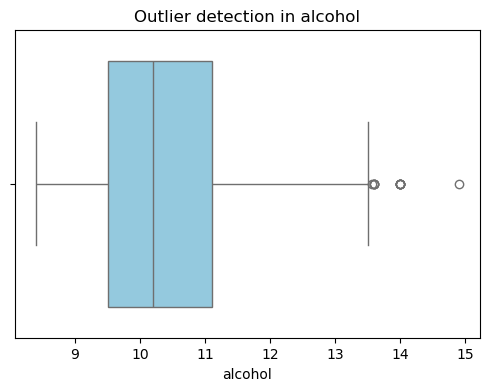

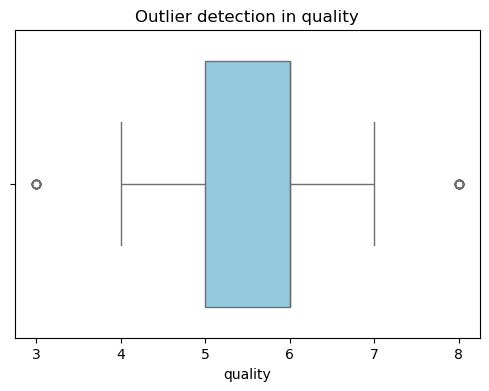

fixed acidity: 49 outliers
citric acid: 1 outliers
residual sugar: 155 outliers
sulphates: 59 outliers
alcohol: 13 outliers
quality: 28 outliers


In [143]:
# outliers 

# Separate numeric and categorical columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

# --- Detect outliers in numeric features using boxplots ---
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col], color="skyblue")
    plt.title(f"Outlier detection in {col}")
    plt.show()

# --- Detect outliers using IQR method ---
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    print(f"{col}: {len(outliers)} outliers")


outliers :
* fixed acidity: 49 outliers
* citric acid: 1 outliers
* residual sugar: 155 outliers
* sulphates: 59 outliers
* alcohol: 13 outliers
* quality: 28 outliers

In [144]:
df.columns

Index(['fixed acidity', 'citric acid', 'residual sugar', 'sulphates',
       'alcohol', 'quality'],
      dtype='object')

## Preprocessing

is the process of getting our dataset ready for model training. In this section, we will perform the following preprocessing steps:

* Data cleaning (lignes(duplicate/non pertinetes)- colonne(redandance/donnees incorrect/nan/outliers)
* Drop and fill missing values (no used)
* Encoding (no used)
* Data trasformation (log transformation) - suppression outliers 
* Feature engineering
* Features Scaling 
* Create Train Test set 


### * Data cleaning 

In [145]:
# Lignes 

#Duplicate 
duplicates = df.duplicated()
print(duplicates)

# Count duplicates
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}") #duplicate rows: 242

0       False
1       False
2       False
3       False
4        True
        ...  
1594    False
1595    False
1596     True
1597    False
1598    False
Length: 1599, dtype: bool
Number of duplicate rows: 242


In [146]:
df = df.drop_duplicates() # remove it 

In [147]:
df.shape # data after removing duplicates

(1357, 6)

### suppression outliers 

In [148]:
# using IQR method
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

mask = pd.Series(True, index=df.index)

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    mask &= (df[col] >= Q1 - 1.5*IQR) & (df[col] <= Q3 + 1.5*IQR)

df = df[mask]


In [149]:
df.shape

(1124, 6)

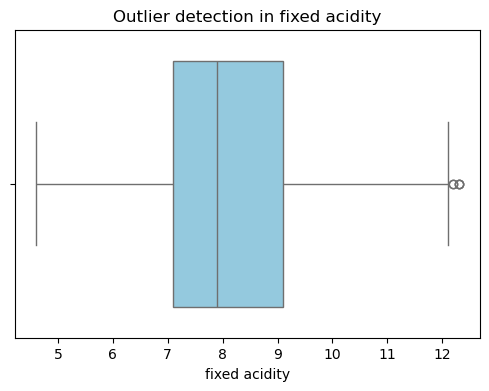

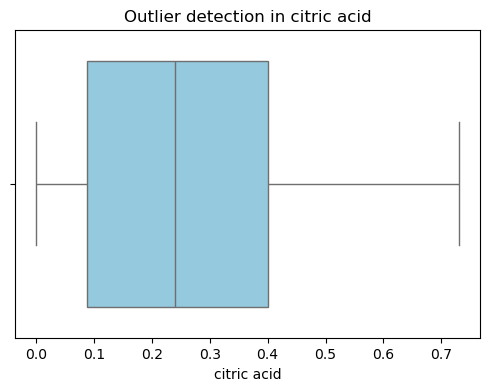

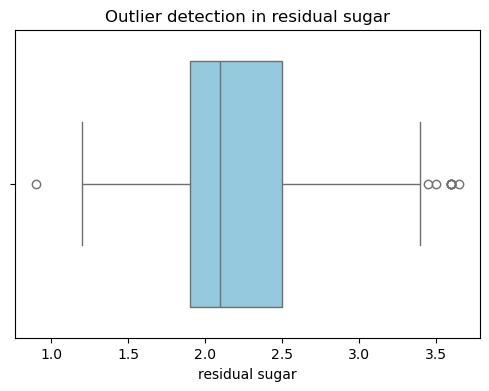

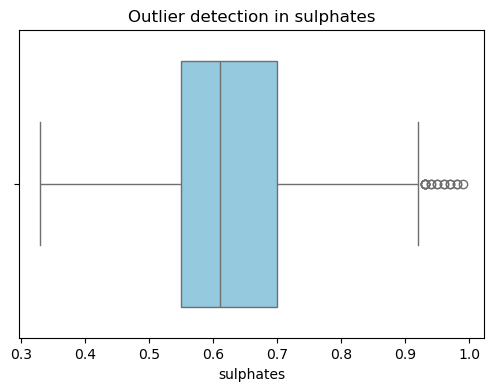

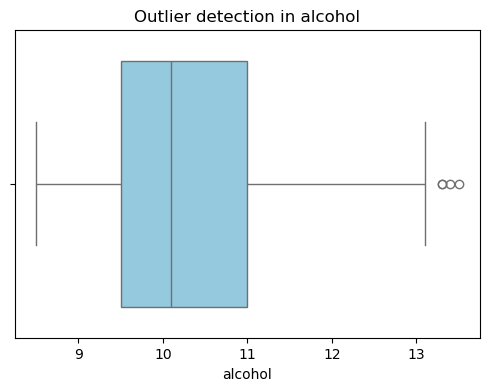

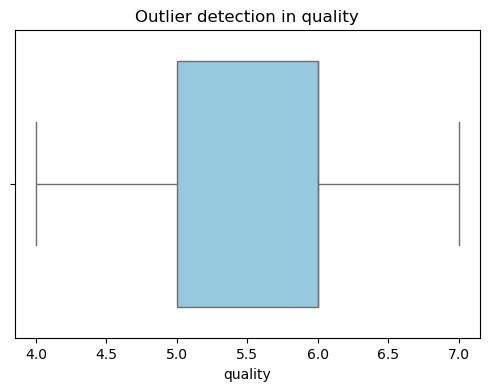

In [150]:
# visuslise each features after eliminte outliers 
numeric_cols = df.select_dtypes(include=['int64','float64']).columns
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col], color="skyblue")
    plt.title(f"Outlier detection in {col}")
    plt.show()

### Feature engineering

Feature engineering is the process of creating new features or modifying existing ones from raw data to improve machine learning model performance. It's often called "the art" of data science because it requires domain knowledge, creativity, and intuition.

In [151]:
df.head(15)

,fixed acidity,citric acid,residual sugar,sulphates,alcohol,quality
0,7.4,0.00,1.9,0.56,9.4,5
1,7.8,0.00,2.6,0.68,9.8,5
2,7.8,0.04,2.3,0.65,9.8,5
3,11.2,0.56,1.9,0.58,9.8,6
5,7.4,0.00,1.8,0.56,9.4,5
6,7.9,0.06,1.6,0.46,9.4,5
7,7.3,0.00,1.2,0.47,10.0,7
8,7.8,0.02,2.0,0.57,9.5,7
10,6.7,0.08,1.8,0.54,9.2,5
12,5.6,0.00,1.6,0.52,9.9,5


### # The balance between alcohol and sugar affects wine perception
* High alcohol with high sugar = sweet wine, low = dry wine
* Balance affects taste perception and quality rating
* Critical for wine style classification

In [176]:
df['alcohol_sugar_ratio'] = df['alcohol'] / (df['residual sugar'] + 1e-6) 

### #Acid Balance (TA/Acidity Ratio)
* Citric acid adds freshness, other acids provide structure
* Balanced acidity is key to wine quality
* Affects wine's aging potential and taste profile

In [177]:
# Creates a measure of acid balance - citric vs fixed acidity
df['citric_acid_ratio'] = df['citric acid'] / (df['fixed acidity'] + 1e-6)
df['non_citric_acidity'] = df['fixed acidity'] - df['citric acid']  # Other acids (tartaric, malic)

### # Sulfur-Acid Interaction
* Sulfates act as preservatives and antioxidants
* Interaction affects wine stability and aging
* Impacts wine's perceived freshness and longevity

In [178]:
df.head()

,fixed acidity,citric acid,residual sugar,sulphates,alcohol,quality,alcohol_sugar_ratio,citric_acid_ratio,non_citric_acidity
0,7.4,0.00,1.9,0.56,9.4,5,4.947366,0.000000,7.40
1,7.8,0.00,2.6,0.68,9.8,5,3.769229,0.000000,7.80
2,7.8,0.04,2.3,0.65,9.8,5,4.260868,0.005128,7.76
3,11.2,0.56,1.9,0.58,9.8,6,5.157892,0.050000,10.64
5,7.4,0.00,1.8,0.56,9.4,5,5.222219,0.000000,7.40


### #Alcohol-Acidity Balance
* High alcohol + low acid = "flabby" wine (poor quality)
* Low alcohol + high acid = "tart" wine
* Balanced wines score higher in quality assessments

### #Sugar-Acid Composite
* Acidity masks sweetness perception
* Residual sugar balances high acidity in some wines
* Critical for wine style and quality perception

In [179]:
df.head()

,fixed acidity,citric acid,residual sugar,sulphates,alcohol,quality,alcohol_sugar_ratio,citric_acid_ratio,non_citric_acidity
0,7.4,0.00,1.9,0.56,9.4,5,4.947366,0.000000,7.40
1,7.8,0.00,2.6,0.68,9.8,5,3.769229,0.000000,7.80
2,7.8,0.04,2.3,0.65,9.8,5,4.260868,0.005128,7.76
3,11.2,0.56,1.9,0.58,9.8,6,5.157892,0.050000,10.64
5,7.4,0.00,1.8,0.56,9.4,5,5.222219,0.000000,7.40


<Axes: >

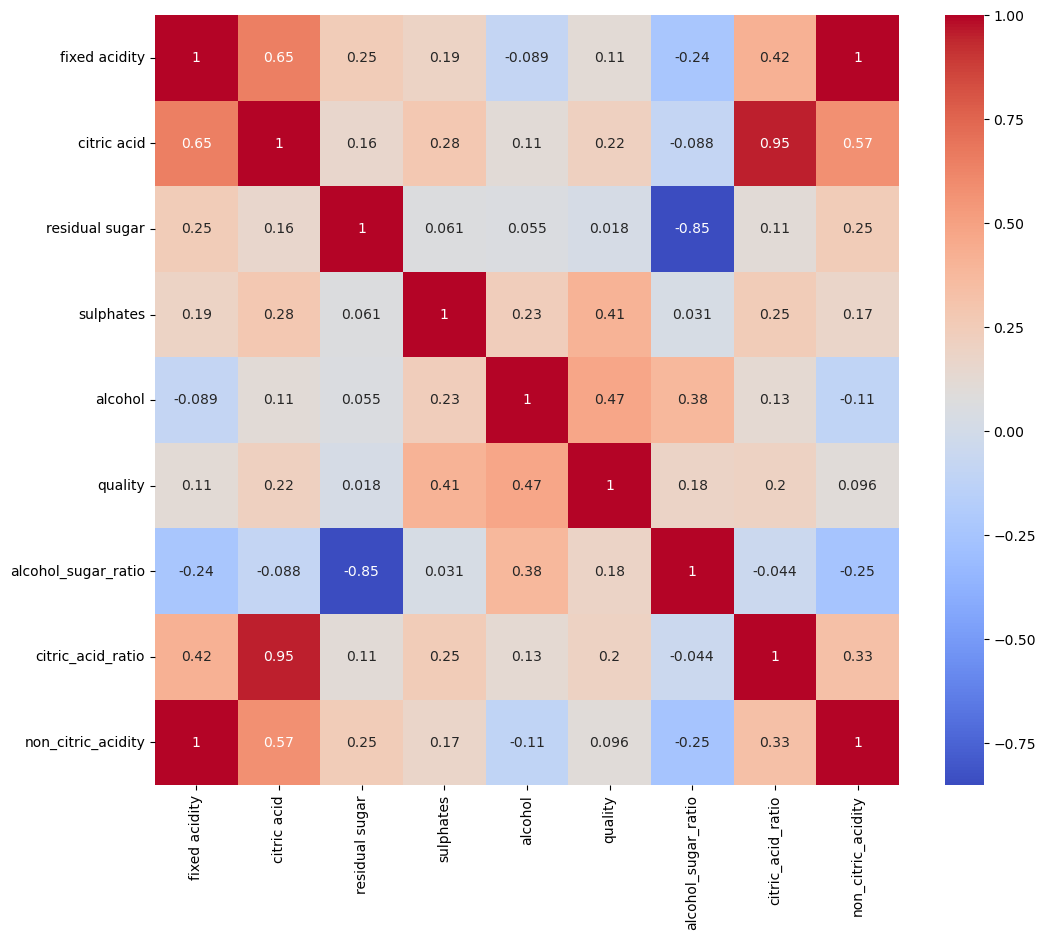

In [180]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm') # this new features have also strong relation with target (target)

### Create Train Test set 

In [181]:
from sklearn.model_selection import train_test_split

x = df.drop(['quality'],axis=1)
y = df['quality']

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.25,random_state=42)

In [182]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(843, 8)
(281, 8)
(843,)
(281,)


## Features Scaling 

* StandardScaler

  
→ rescales to mean = 0, std = 1 (good for algorithms assuming Gaussian distribution, e.g. Logistic Regression, SVM).

* MinMaxScaler

 → rescales to [0,1] (good for algorithms sensitive to magnitude, e.g. Neural Networks, KNN).

In [183]:
# StandardScaler
from sklearn.preprocessing import StandardScaler

# Apply scaling
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


## Modelling  

In [184]:
# Machine learning models
from sklearn.linear_model import LogisticRegression, SGDClassifier

from sklearn.svm import SVC, LinearSVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.tree import DecisionTreeClassifier

# Model evaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [185]:
# model 1 : Logistic Regression

In [186]:
lr = LogisticRegression()

lr.fit(x_train,y_train)

y_pred_train_lr = lr.predict(x_train)
y_pred_test_lr = lr.predict(x_test)

accuracy_score_train_lr = accuracy_score(y_train,y_pred_train_lr)
accuracy_score_test_lr = accuracy_score(y_test,y_pred_test_lr)

print(accuracy_score_train_lr)
print(accuracy_score_test_lr)

0.608540925266904
0.5800711743772242


In [187]:
#model 2 : SVC

In [188]:
svc_classifier = SVC()
svc_classifier.fit(x_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [189]:
y_pred_svc = svc_classifier.predict(x_test)

In [190]:
accuracy_score_svc = accuracy_score(y_test,y_pred_svc)
print(accuracy_score_svc)

0.5836298932384342


In [191]:
# model 3:DecisionTreeClassifier

In [192]:
# Decision Tree Classifier
dt_classifier = DecisionTreeClassifier()

dt_classifier.fit(x_train, y_train)

y_pred_train_dt = dt_classifier.predict(x_train)
y_pred_test_dt = dt_classifier.predict(x_test)

accuracy_score_train_dt = accuracy_score(y_train, y_pred_train_dt)
accuracy_score_test_dt = accuracy_score(y_test, y_pred_test_dt)

print("Decision Tree Classifier:")
print(accuracy_score_train_dt)
print(accuracy_score_test_dt)  # overfitting here 

Decision Tree Classifier:
0.9988137603795967
0.5338078291814946


In [193]:
# model 4 :K-NEAREST NEIGHBORS CLASSIFIER

In [194]:
# K-Nearest Neighbors Classifier
knn_classifier = KNeighborsClassifier()

knn_classifier.fit(x_train, y_train)

y_pred_train_knn = knn_classifier.predict(x_train)
y_pred_test_knn = knn_classifier.predict(x_test)

accuracy_score_train_knn = accuracy_score(y_train, y_pred_train_knn)
accuracy_score_test_knn = accuracy_score(y_test, y_pred_test_knn)

print("K-Nearest Neighbors Classifier:")
print(accuracy_score_train_knn)
print(accuracy_score_test_knn)

K-Nearest Neighbors Classifier:
0.6820877817319099
0.5693950177935944


In [195]:
# model 5 :RANDOM FOREST CLASSIFIER

In [196]:
# Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', random_state=0)

rf_classifier.fit(x_train, y_train)

y_pred_train_rf = rf_classifier.predict(x_train)
y_pred_test_rf = rf_classifier.predict(x_test)

accuracy_score_train_rf = accuracy_score(y_train, y_pred_train_rf)
accuracy_score_test_rf = accuracy_score(y_test, y_pred_test_rf)

print("Random Forest Classifier:")
print(accuracy_score_train_rf)
print(accuracy_score_test_rf)

Random Forest Classifier:
0.9988137603795967
0.5693950177935944


In [197]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,  # Stochastic gradient boosting
    random_state=42
)

gb_model.fit(x_train, y_train)

y_pred_train_gb = gb_model.predict(x_train)
y_pred_test_gb = gb_model.predict(x_test)

accuracy_score_train_gb = accuracy_score(y_train, y_pred_train_gb)
accuracy_score_test_gb = accuracy_score(y_test, y_pred_test_gb)

print("Random Forest Classifier:")
print(accuracy_score_train_gb)
print(accuracy_score_test_gb)

Random Forest Classifier:
0.8920521945432978
0.5693950177935944


## Problem :
* train give higher score n test give lower score 
* This is classic overfitting
* model is memorizing the training data instead of learning patterns.

### Cross-Validation to Check Real Performance

In [198]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

# Define the model FIRST
rf_fixed = RandomForestClassifier(
    n_estimators=100,      # Reduce from 1000
    max_depth=10,          # Limit tree depth
    min_samples_split=10,  # Require more samples to split
    min_samples_leaf=5,    # Require more samples in leaves
    max_features='sqrt',   # Limit features per split
    random_state=42
)

# Now run cross-validation
cv_scores = cross_val_score(rf_fixed, x_train, y_train, cv=5)
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {cv_scores.mean():.4f}")
print(f"CV standard deviation: {cv_scores.std():.4f}")

# Then train and test
rf_fixed.fit(x_train, y_train)
train_acc = rf_fixed.score(x_train, y_train)
test_acc = rf_fixed.score(x_test, y_test)

print(f"\nFinal results:")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Gap: {train_acc - test_acc:.4f}")

Cross-validation scores: [0.60946746 0.60946746 0.55621302 0.63095238 0.58333333]
Mean CV accuracy: 0.5979
CV standard deviation: 0.0257

Final results:
Train Accuracy: 0.7877
Test Accuracy: 0.5943
Gap: 0.1934


In [199]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Bagging with very simple base trees
base_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20)
bagging_model = BaggingClassifier(
    base_tree,
    n_estimators=50,
    max_samples=0.8,      # Use 80% of data per tree
    max_features=0.5,     # Use 50% of features per tree
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(x_train, y_train)
print(f"Bagging: Train={bagging_model.score(x_train, y_train):.4f}, Test={bagging_model.score(x_test, y_test):.4f}")

Bagging: Train=0.6429, Test=0.5907


In [200]:
# it wasnt good results yet it was stil great to learn new things (wisdom)